# Zaawansowana Analiza Ryzyka Udaru Mózgu i System Wspomagania Decyzji Klinicznych (CDSS)
### Kompleksowy Raport Badawczo-Wdrożeniowy: Od Biostatystyki do Wyjaśnialnego Uczenia Maszynowego (XAI)

**Autor:** Antoni Pieszczoch
**Środowisko:** Python 3.12 | Scikit-Learn | LightGBM | XGBoost | SHAP | Statsmodels  
**Zgodność:** Lokalne środowisko projektowe oraz platforma Google Colaboratory (automatyczna detekcja ścieżek i pobieranie danych)

---

### Spis Rozdziałów
1. **Rozdział 1:** Wstęp i cele projektu
2. **Rozdział 2:** Przegląd literatury i stan wiedzy
3. **Rozdział 3:** Charakterystyka danych i przygotowanie kohorty
4. **Rozdział 4:** Analiza biostatystyczna (Tabela 1 i wielowymiarowa regresja logistyczna)
5. **Rozdział 5:** Budowa i ewaluacja modeli uczenia maszynowego (5-Fold CV, SMOTE vs Cost-Sensitive, optymalizacja $F_2$)
6. **Rozdział 6:** Wyjaśnialna sztuczna inteligencja (XAI — globalna ważność i studia przypadków SHAP Waterfall)
7. **Rozdział 7:** System wspomagania decyzji klinicznych (CDSS — wiek naczyniowy, centyle populacyjne, symulator What-If i akronim U.D.A.R.)
8. **Rozdział 8:** Dyskusja i ograniczenia pracy
9. **Rozdział 9:** Podsumowanie i wnioski kliniczne
10. **Rozdział 10:** Bibliografia

In [1]:
# ==============================================================================
# Inicjalizacja środowiska obliczeniowego, importy bibliotek i obsługa ścieżek
# ==============================================================================
import os
import sys
import warnings
from pathlib import Path

# Wyciszenie ostrzeżeń deprecation i formatowania dla czystości raportu
warnings.filterwarnings('ignore')

# Automatyczna detekcja katalogu głównego projektu (kompatybilność z Google Colab oraz lokalnym repozytorium)
current_dir = Path.cwd().resolve()
if (current_dir / "src").is_dir():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "src").is_dir():
    PROJECT_ROOT = current_dir.parent
else:
    PROJECT_ROOT = current_dir

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfiguracja estetyki wykresów w standardzie publikacyjnym
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

print(f"✓ Środowisko skonfigurowane pomyślnie.")
print(f"✓ Ścieżka główna projektu: {PROJECT_ROOT}")

✓ Środowisko skonfigurowane pomyślnie.
✓ Ścieżka główna projektu: /Users/antonipieszczoch/Desktop/Repos/MedycznaAnaliza-ticket-30


---
## Rozdział 1: Wstęp i cele projektu

### 1.1 Epidemiologia udarów mózgu na świecie i w Polsce
Udar mózgu (ang. *stroke*) stanowi drugą najczęstszą przyczynę zgonów na świecie (odpowiadając za ok. 11% wszystkich zgonów wg Światowej Organizacji Zdrowia — WHO) oraz wiodącą przyczynę trwałego inwalidztwa i utraty samodzielności u osób dorosłych. W ujęciu patofizjologicznym wyróżnia się udary niedokrwienne (ok. 85% przypadków), wywołane nagłym zablokowaniem przepływu krwi w naczyniu domózgowym lub mózgowym przez zakrzep lub zator, oraz udary krwotoczne (ok. 15%), wynikające z pęknięcia naczynia krwionośnego.

W Polsce co roku dochodzi do około **70 000 – 80 000 incydentów naczyniowo-mózgowych**. Pomimo dynamicznego rozwoju sieci oddziałów udarowych, powszechności leczenia trombolitycznego (rt-PA) i trombektomii mechanicznej, śmiertelność 30-dniowa wciąż przekracza 15%, a niemal 50% pacjentów, którzy przeżyli fazę ostrą, pozostaje w różnym stopniu niesamodzielnych w codziennych czynnościach życiowych (wskaźnik mRS $\ge 3$).

### 1.2 Obciążenie społeczno-ekonomiczne
Koszty generowane przez udary mózgu dzielą się na:
* **Koszty bezpośrednie:** hospitalizacje na oddziałach intensywnej terapii i oddziałach udarowych, procedury rewaskularyzacyjne, diagnostyka neuroobrazowa (TK/MRI), leczenie powikłań oraz wczesna i przewlekła rehabilitacja neurologiczna.
* **Koszty pośrednie:** utrata produktywności pacjenta i jego opiekunów prawnych/rodziny, przedwczesna umieralność, długoterminowe renty z tytułu niezdolności do pracy i koszty opieki instytucjonalnej. W skali europejskiej roczny koszt opieki poudarowej szacuje się na ponad 60 miliardów euro.

### 1.3 Znaczenie prewencji pierwotnej
Badania populacyjne (w tym przełomowe badanie INTERSTROKE) dowodzą, że **aż 90% ryzyka udaru mózgu zależy od dziesięciu modyfikowalnych czynników ryzyka**. Wśród nich najistotniejszą rolę odgrywają:
1. Nadciśnienie tętnicze (odpowiadające za blisko 50% udarów),
2. Zaburzenia gospodarki węglowodanowej (cukrzyca i stany przedcukrzycowe),
3. Otyłość i nieprawidłowa masa ciała (BMI $\ge 25\text{ kg/m}^2$),
4. Palenie tytoniu,
5. Schorzenia sercowo-naczyniowe (migotanie przedsionków, choroba wieńcowa).

Skuteczna prewencja pierwotna, oparta na wczesnej identyfikacji osób z grupy wysokiego ryzyka i agresywnej kontroli biomarkerów, ma kluczowe znaczenie epidemiologiczne.

### 1.4 Rola systemów wspomagania decyzji klinicznych (CDSS) w POZ
Lekarz Podstawowej Opieki Zdrowotnej (POZ) dysponuje ograniczonym czasem podczas standardowej wizyty (średnio 12–15 minut na pacjenta). W tym oknie czasowym musi zsyntetyzować dane z wywiadu, badań fizykalnych i laboratoryjnych. Tradycyjne skale punktowe bywają uciążliwe w kalkulacji lub zbyt uproszczone. 

Wdrożenie **Klinicznych Systemów Wspomagania Decyzji (CDSS — *Clinical Decision Support Systems*)** umożliwia:
* Błyskawiczną, zautomatyzowaną stratyfikację ryzyka na podstawie rutynowo gromadzonych danych w gabinecie lekarza rodzinnego,
* Obiektywizację wskazań do pogłębionej diagnostyki kardiologicznej/neurologicznej,
* Skuteczną komunikację ryzyka z pacjentem poprzez intuicyjne metafory kliniczne (np. pojęcie **Wieku Naczyniowego** zamiast abstrakcyjnych procentów),
* Interaktywne symulacje korzyści z modyfikacji stylu życia (What-If Analysis).

### 1.5 Cele badawcze i hipotezy projektu
Niniejszy projekt ma na celu opracowanie, rygorystyczną walidację i implementację kliniczną systemu predykcji ryzyka udaru mózgu. Formułujemy następujące hipotezy badawcze:
1. **Hipoteza 1 (Metodologiczna):** W zbiorach danych medycznych o udarach braki danych wskaźnika BMI nie mają charakteru losowego (MNAR/MAR), a ich bezrefleksyjne usuwanie prowadzi do błędu selekcyjnego (*selection bias*).
2. **Hipoteza 2 (Algorytmiczna):** W warunkach skrajnej asymetrii klas standardowy próg klasyfikacyjny $p=0.50$ skutkuje niedopuszczalnie niską czułością (*Recall*). Zastosowanie optymalizacji progu pod kątem metryki $F_2$-score pozwala radykalnie ograniczyć liczbę wyników fałszywie ujemnych (FN) przy akceptowalnym poziomie precyzji.
3. **Hipoteza 3 (Kliniczna/XAI):** Zastosowanie metod wyjaśnialnej sztucznej inteligencji (XAI — algorytmy SHAP) oraz kalkulatora Wieku Naczyniowego pozwala przekształcić model uczenia maszynowego w bezpieczne i transparentne narzędzie gabinetowe.

---
## Rozdział 2: Przegląd literatury i stan wiedzy

### 2.1 Klasyczne narzędzia oceny ryzyka sercowo-naczyniowego i udarowego
Współczesna kardiologia i angiologia prewencyjna opierają się na kilku uznanych narzędziach stratyfikacji:
* **Framingham Stroke Risk Profile (FSRP):** Klasyczny model opracowany na populacji kohorty Framingham, uwzględniający wiek, skurczowe ciśnienie tętnicze, leczenie hipotensyjne, cukrzycę, palenie tytoniu, przerost lewej komory serca w EKG oraz współistniejące choroby serca. Choć sprawdzony historycznie, FSRP wykazuje tendencję do niedoszacowania ryzyka w populacjach o innej strukturze etnicznej i socjoekonomicznej niż amerykańska klasa średnia z lat 70. XX wieku.
* **Karta SCORE / SCORE2 (Systematic Coronary Risk Evaluation):** Rekomendowana przez Europejskie Towarzystwo Kardiologiczne (ESC) do szacowania 10-letniego ryzyka pierwszego śmiertelnego i nieśmiertelnego incydentu sercowo-naczyniowego u osób w wieku 40–69 lat w Europie. Polska jest w SCORE2 sklasyfikowana w grupie wysokiego ryzyka sercowo-naczyniowego.
* **Skala $\text{CHA}_2\text{DS}_2\text{-VASc}$:** Narzędzie dedykowane specyficznie pacjentom z niezastawkowym migotaniem przedsionków w celu kwalifikacji do doustnego leczenia przeciwkrzepliwego (OAC/NOAC).

### 2.2 Ograniczenia tradycyjnych modeli liniowych w medycynie
Klasyczne skale ryzyka opierają się najczęściej na liniowych modelach proporcjonalnego hazardu Coxa lub prostej regresji logistycznej z arbitralnie przypisanymi wagami punktowymi. Narzędzia te cechują istotne ograniczenia:
1. **Założenie addytywności i liniowości:** Modele liniowe z trudem wychwytują złożone, nieliniowe interakcje między biomarkerami (np. synergistyczny, multiplikatywny efekt jednoczesnego występowania otyłości, hiperglikemii i palenia tytoniu).
2. **Kategoryzacja zmiennych ciągłych:** Częsta praktyka podziału zmiennych ciągłych (np. ciśnienie krwi czy poziom glukozy) na sztywne przedziały powoduje utratę cennych informacji wariancyjnych i powstawanie sztucznych progów decyzyjnych tuż przy granicach przedziałów.
3. **Niska adaptacyjność:** Tradycyjne kalkulatory są statyczne i trudne do rekalibracji w nowych populacjach lokalnych.

### 2.3 Wyzwanie asymetrii klas (Class Imbalance) w badaniach przesiewowych
W populacji ogólnej poddawanej badaniom przesiewowym roczna zapadalność na udar wynosi ułamek procenta, a w badaniach przekrojowych odsetek osób z przebytym udarem rzadko przekracza 3–6%. 

W uczeniu maszynowym sytuacja ta określana jest jako **drastyczna asymetria klas** (*severe class imbalance*):
* Naiwny klasyfikator przypisujący każdemu pacjentowi klasę 0 (brak udaru) osiągnie pozornie imponującą dokładność (*Accuracy*) rzędu 95%, będąc jednocześnie całkowicie bezużytecznym medycznie (czułość równa 0%).
* Standardowa krzywa ROC-AUC może w takich warunkach dawać nadmiernie optymistyczny obraz jakości klasyfikatora, ponieważ w mianowniku wskaźnika FPR (*False Positive Rate*) znajduje się dominująca liczebnie klasa większościowa.
* W medycynie przesiewowej złotym standardem oceny modeli jest **pole pod krzywą Precision-Recall (PR-AUC)** oraz metryka **$F_2$-score**, w której koszt błędu fałszywie ujemnego (niezdiagnozowany pacjent zagrożony udarem) jest wyceniany 2-krotnie wyżej niż błąd fałszywie dodatni (skierowanie zdrowego pacjenta na rutynową kontrolę).

### 2.4 Rola nowoczesnego uczenia maszynowego (ML) i technik próbkowania
Zespołowe algorytmy drzewiaste — **Random Forest, XGBoost oraz LightGBM** — charakteryzują się wysoką zdolnością do modelowania nieliniowości i odpornością na wartości odstające. Aby skompensować asymetrię klas, stosuje się:
* **Metody ważenia wrażliwego na koszt (Cost-Sensitive Learning):** Zwiększenie wagi błędu popełnianego na klasie mniejszościowej proporcjonalnie do stosunku klas ($w_1 / w_0 \approx N_0 / N_1$).
* **Syntetyczne nadpróbkowanie (SMOTE — Synthetic Minority Over-sampling Technique):** Generowanie syntetycznych obserwacji klasy mniejszościowej w przestrzeni cech poprzez interpolację między najbliższymi sąsiadami wewnątrz pętli walidacji krzyżowej.

---
## Rozdział 3: Charakterystyka danych i przygotowanie kohorty

### 3.1 Źródło danych i wczytanie
W badaniu wykorzystano powszechnie uznany zbiór referencyjny *Stroke Prediction Dataset* (udostępniony na platformie Kaggle / FedSor). Zbiór obejmuje 5110 rekordów pacjentów opisanych 12 atrybutami, w tym cechami demograficznymi, współistniejącymi chorobami kardiologicznymi, biomarkerami laboratoryjnymi i stylem życia.

Nasz potok danych (`src.data`) implementuje automatyczną detekcję środowiska: w przypadku uruchomienia w Google Colaboratory lub na nowej maszynie bez lokalnych plików CSV, skrypt pobiera dane bezpośrednio z oficjalnego repozytorium zdalnego z mechanizmem rezerwowego serwera lustrzanego (fallback mirror).

In [2]:
# ==============================================================================
# Rozdział 3.1: Wczytanie surowych danych i wstępna inspekcja
# ==============================================================================
from src.data import load_data

raw_df = load_data()

print(f"Liczba wczytanych rekordów (N): {len(raw_df)}")
print(f"Liczba atrybutów: {raw_df.shape[1]}")
print(f"Atrybuty w zbiorze: {list(raw_df.columns)}")

# Podgląd pierwszych wierszy zbioru
raw_df.head(5)

Liczba wczytanych rekordów (N): 5110
Liczba atrybutów: 12
Atrybuty w zbiorze: ['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


### 3.2 Segregacja kohorty dorosłych i podkohorty pediatrycznej
Fundamentalną zasadą biostatystyki klinicznej jest zachowanie jednorodności patofizjologicznej badanej grupy. W analizowanym zbiorze wiek pacjentów waha się od 0.08 roku (niemowlęta) do 82 lat.

**Kliniczne uzasadnienie odcięcia kohorty dorosłych ($\text{wiek} \ge 18$ lat):**
1. **Całkowicie odmienna etiologia udaru u dzieci:** Udary pediatryczne stanowią rzadkie jednostki chorobowe (zapadalność rzędu 2–3 / 100 000 dzieci rocznie). Ich przyczynami są wrodzone wady serca, arteriopatie mózgowe (np. choroba Moyamoya), zakażenia ośrodkowego układu nerwowego oraz uwarunkowane genetycznie trombofilie. U dzieci miażdżyca naczyń, nadciśnienie pierwotne czy wieloletnie palenie tytoniu w zasadzie nie występują jako czynniki sprawcze.
2. **Rozkład empiryczny w podkohorcie pediatrycznej:** W analizowanym zbiorze znajduje się **856 dzieci i młodzieży poniżej 18. roku życia**, wśród których odnotowano zaledwie **2 incydenty udarowe**. Włączenie tej grupy do modeli predykcyjnych dla dorosłych sztucznie zawyżyłoby wagę wieku i wprowadziło artefakty do kalkulatorów ryzyka.
3. **Singleton 'Other' gender:** Rekord o identyfikatorze `id = 56156` posiada płeć zakodowaną jako 'Other'. Ze względu na brak reprezentacji statystycznej (pojedynczy przypadek na 5110 rekordów), rekord ten został usunięty z kohorty modelowej, aby uniknąć błędów podczas kodowania one-hot wewnątrz foldów walidacji.

Finalna kohorta dorosłych wynosi zatem **$N = 4253$ pacjentów**, z czego **247 przebyło udar mózgu (prewalencja 5.81%)**.

In [3]:
# ==============================================================================
# Rozdział 3.2: Kuracja kohort z wykorzystaniem modułu src.data
# ==============================================================================
from src.data import curate_stroke_data

cohorts = curate_stroke_data(raw_df, remove_other_gender=True, age_threshold=18.0)
adult_df = cohorts.adult
paed_df = cohorts.paediatric

print("=" * 60)
print(f"KOHORTA DOROSŁYCH (Wiek >= 18 lat, po usunięciu 'Other'):")
print(f"  • Całkowita liczebność (N): {len(adult_df)}")
print(f"  • Przypadki udaru (stroke = 1): {adult_df['stroke'].sum()} ({adult_df['stroke'].mean()*100:.2f}%)")
print(f"  • Grupa kontrolna (stroke = 0): {(adult_df['stroke'] == 0).sum()} ({(1-adult_df['stroke'].mean())*100:.2f}%)")
print("-" * 60)
print(f"PODKOHORTA PEDIATRYCZNA (Wiek < 18 lat, eksploracyjna):")
print(f"  • Całkowita liczebność (N): {len(paed_df)}")
print(f"  • Przypadki udaru (stroke = 1): {paed_df['stroke'].sum()} ({paed_df['stroke'].mean()*100:.2f}%)")
print("=" * 60)

KOHORTA DOROSŁYCH (Wiek >= 18 lat, po usunięciu 'Other'):
  • Całkowita liczebność (N): 4253
  • Przypadki udaru (stroke = 1): 247 (5.81%)
  • Grupa kontrolna (stroke = 0): 4006 (94.19%)
------------------------------------------------------------
PODKOHORTA PEDIATRYCZNA (Wiek < 18 lat, eksploracyjna):
  • Całkowita liczebność (N): 856
  • Przypadki udaru (stroke = 1): 2 (0.23%)


### 3.3 Dogłębna weryfikacja nielosowości braków danych BMI (MNAR/MAR)
Jedynym atrybutem zawierającym brakujące wartości w zbiorze danych jest wskaźnik masy ciała — **BMI (`bmi`)**. Standardowym (i wysoce szkodliwym) podejściem w wielu naiwnych projektach data science jest mechaniczne usuwanie wierszy z brakami danych (*listwise deletion / dropna*).

Poniższa analiza wykazuje, że braki BMI w badaniach udarów **nie mają charakteru całkowicie losowego (MCAR — Missing Completely At Random)**:
* W kohorcie dorosłych z udarem mózgu brak wartości BMI odnotowano u **39 z 247 pacjentów (aż 15.79%)**!
* W kohorcie dorosłych bez udaru mózgu brak BMI wystąpił jedynie u **141 z 4006 pacjentów (3.52%)**.
* Test chi-kwadrat Pearsona wykazuje skrajnie istotną statystycznie zależność między statusem udaru a faktem braku pomiaru BMI ($p < 0.0001$).

**Mechanizm kliniczny:** Pacjenci przywożeni na szpitalny oddział ratunkowy w stanie ostrego udaru mózgu (często z zaburzeniami świadomości, niedowładem połowiczym lub w stanie zagrożenia życia) nie są w stanie stanąć na standardowej wadze medycznej, a ratowanie tkanki mózgowej (*time is brain*) ma bezwzględny priorytet nad pomiarami antropometrycznymi. Usunięcie wierszy z brakami BMI oznaczałoby wyeliminowanie blisko 16% najciężej chorych pacjentów z udarem, prowadząc do zafałszowania wyników modelu (*selection bias*).

**Rozwiązanie metodologiczne:** Wdrożenie nieszczelnego (*leak-free*) potoku imputacji opartego na algorytmie **KNNImputer ($k=5$)**, dopasowywanego ściśle na danych treningowych każdego foldu walidacji krzyżowej.

In [4]:
# ==============================================================================
# Rozdział 3.3: Weryfikacja nielosowości braków BMI w kohortach
# ==============================================================================
from scipy.stats import chi2_contingency
from src.data import validate_missing_bmi_patterns

# Generowanie publikacyjnej tabeli braków BMI
bmi_patterns_df = validate_missing_bmi_patterns(raw_df)
print("Struktura braków wskaźnika BMI w badanych kohortach:")
display(bmi_patterns_df)

# Formalny test hipotezy o nielosowości braków danych BMI u dorosłych
contingency_table = pd.crosstab(
    adult_df['stroke'], 
    adult_df['bmi'].isna(), 
    rownames=['Udar mózgu'], 
    colnames=['Brak wartości BMI']
)
chi2, p_val, dof, _ = chi2_contingency(contingency_table)

print("\n" + "=" * 60)
print("TEST NIEZALEŻNOŚCI CHI-KWADRAT (Status udaru vs obecność braku BMI):")
print(f"  • Tabela kontyngencji:\n{contingency_table}")
print(f"  • Statystyka chi-kwadrat: {chi2:.2f} (stopnie swobody = {dof})")
print(f"  • Wartość p: {p_val:.2e} ({'<0.0001' if p_val < 0.0001 else f'{p_val:.4f}'})")
print("  • WNIOSEK: Odrzucamy hipotezę o losowości braków (MCAR).")
print("    Braki mają charakter nielosowy (MNAR/MAR) i wymagają imputacji wewnątrz CV!")
print("=" * 60)

Struktura braków wskaźnika BMI w badanych kohortach:


,Cohort,Total (N),Missing BMI (n),Missing BMI (%),Observed BMI (n)
0,Overall Dataset,5110,201,3.93%,4909
1,Adults Overall (age >= 18),4254,181,4.25%,4073
2,Adults Non-Stroke (stroke = 0),4007,142,3.54%,3865
3,Adults Stroke (stroke = 1),247,39,15.79%,208
4,Paediatric Overall (age < 18),856,20,2.34%,836
5,Paediatric Non-Stroke (stroke = 0),854,19,2.22%,835
6,Paediatric Stroke (stroke = 1),2,1,50.00%,1



TEST NIEZALEŻNOŚCI CHI-KWADRAT (Status udaru vs obecność braku BMI):
  • Tabela kontyngencji:
Brak wartości BMI  False  True 
Udar mózgu                     
0                   3864    142
1                    208     39
  • Statystyka chi-kwadrat: 82.63 (stopnie swobody = 1)
  • Wartość p: 9.89e-20 (<0.0001)
  • WNIOSEK: Odrzucamy hipotezę o losowości braków (MCAR).
    Braki mają charakter nielosowy (MNAR/MAR) i wymagają imputacji wewnątrz CV!


---
## Rozdział 4: Analiza biostatystyczna

### 4.1 Publikacyjna Tabela 1 (Baseline Characteristics)
Zgodnie ze standardami wytycznych STROBE (*Strengthening the Reporting of Observational Studies in Epidemiology*) oraz rekomendacjami wiodących czasopism medycznych (np. *The Lancet Neurology*, *Stroke*), punktem wyjścia do analizy jest wygenerowanie sformalizowanej **Tabeli 1 (Baseline Table 1)**.

Dla każdej cechy klinicznej wyliczono:
* Dla zmiennych ciągłych: średnią z odchyleniem standardowym ($\text{Mean} \pm \text{SD}$) oraz medianę z rozstępem międzykwartylowym ($\text{Median [IQR]}$).
* Test normalności i jednorodności wariancji: **test Levene'a** decydujący o wyborze standardowego testu t-Studenta (przy równej wariancji) lub **testu t-Welcha** (przy heteroskedastyczności).
* Dla zmiennych kategorycznych: liczności i odsetki ($n\ [\%]$) z weryfikacją istotności testem **chi-kwadrat Pearsona**.

In [5]:
# ==============================================================================
# Rozdział 4.1: Generowanie pełnej publikacyjnej Tabeli 1
# ==============================================================================
from src.biostats import generate_table_one

table_one_df = generate_table_one(adult_df, stratify_by="stroke")

print(f"Tabela 1: Charakterystyka wyjściowa dorosłej kohorty badawczej (N = {len(adult_df)})")
display(table_one_df)

Tabela 1: Charakterystyka wyjściowa dorosłej kohorty badawczej (N = 4253)


,Variable,Metric / Level,"Overall (N=4,253)","No Stroke (N=4,006)",Stroke (N=247),p-value,Test
0,age,Mean ± SD,50.21 ± 17.83,49.10 ± 17.55,68.21 ± 11.55,<0.001,Welch's t-test
1,age,Median [IQR],51.00 [36.00 - 64.00],49.00 [35.00 - 62.00],71.00 [59.00 - 78.00],,
2,avg_glucose_level,Mean ± SD,108.51 ± 47.77,106.99 ± 46.35,133.10 ± 61.86,<0.001,Welch's t-test
3,avg_glucose_level,Median [IQR],92.44 [77.48 - 116.12],91.94 [77.33 - 114.32],105.92 [80.28 - 196.81],,
4,bmi,Mean ± SD,30.43 ± 7.23,30.43 ± 7.28,30.47 ± 6.34,0.944,Student's t-test
5,bmi,Median [IQR],29.20 [25.40 - 34.20],29.20 [25.40 - 34.20],29.65 [26.40 - 33.70],,
6,hypertension,0,"3,756 (88.3%)","3,575 (89.2%)",181 (73.3%),<0.001,Pearson Chi-square
7,hypertension,1,497 (11.7%),431 (10.8%),66 (26.7%),,
8,heart_disease,0,"3,978 (93.5%)","3,778 (94.3%)",200 (81.0%),<0.001,Pearson Chi-square
9,heart_disease,1,275 (6.5%),228 (5.7%),47 (19.0%),,


### 4.2 Wielowymiarowa regresja logistyczna (Multivariable Logistic Regression)
Aby zbadać niezależny wpływ poszczególnych czynników ryzyka przy jednoczesnej kontroli potencjalnych czynników zakłócających (*confounders*), dopasowano wielowymiarowy model regresji logistycznej:

$$\ln\left(\frac{P(\text{udar})}{1 - P(\text{udar})}\right) = \beta_0 + \beta_1 \cdot \text{Wiek} + \beta_2 \cdot \text{Glukoza} + \beta_3 \cdot \text{BMI} + \beta_4 \cdot \text{Nadciśnienie} + \beta_5 \cdot \text{Choroba Serca} + \dots$$

Dla każdego atrybutu wyliczono:
* Współczynnik regresji $\beta$ wraz z błędem standardowym (SE),
* Wartość statystyki z-Walda oraz wartość $p$,
* **Skorygowany iloraz szans (aOR — *adjusted Odds Ratio*):** $\text{aOR} = e^\beta$,
* **95% przedział ufności (95% CI):** $[e^{\beta - 1.96 \cdot \text{SE}}, e^{\beta + 1.96 \cdot \text{SE}}]$.

In [6]:
# ==============================================================================
# Rozdział 4.2: Dopasowanie wielowymiarowej regresji logistycznej
# ==============================================================================
from src.biostats import fit_multivariable_logistic_regression

reg_results_df, logit_model = fit_multivariable_logistic_regression(adult_df, return_model=True)

print("Wyniki wielowymiarowej analizy regresji logistycznej:")
display(reg_results_df[['label_pl', 'coef', 'std_err', 'z_value', 'p_value', 'or', 'ci_lower', 'ci_upper', 'is_significant']])

Wyniki wielowymiarowej analizy regresji logistycznej:


,label_pl,coef,std_err,z_value,p_value,or,ci_lower,ci_upper,is_significant
0,Nadciśnienie tętnicze,0.388430,0.164434,2.362227,1.816550e-02,1.474664,1.068382,2.035445,True
1,Palenie: Aktywni palacze,0.317422,0.205188,1.546983,1.218674e-01,1.373582,0.918752,2.053574,False
2,Choroba serca,0.288801,0.190355,1.517171,1.292235e-01,1.334826,0.919167,1.938452,False
3,Palenie: Byli palacze,0.194735,0.175336,1.110637,2.667246e-01,1.214989,0.861640,1.713243,False
4,Palenie: Nieznane,0.130151,0.198830,0.654587,5.127334e-01,1.139001,0.771400,1.681776,False
5,Wiek (lata),0.071054,0.005711,12.441809,1.549534e-35,1.073640,1.061689,1.085725,True
6,Płeć (Mężczyzna),0.034945,0.142009,0.246076,8.056238e-01,1.035563,0.783968,1.367901,False
7,Poziom glukozy (mg/dl),0.004158,0.001194,3.481562,4.984977e-04,1.004166,1.001819,1.006519,True
8,BMI (kg/m²),0.001684,0.011395,0.147798,8.825022e-01,1.001686,0.979562,1.024308,False


### 4.3 Publikacyjny Wykres Leśny (Forest Plot)
Wizualizacja skorygowanych ilorazów szans (aOR) na skali logarytmicznej stanowi kanon prezentacji wyników biostatystycznych w literaturze medycznej. Pionowa linia przerywana przy wartości $\text{aOR} = 1.0$ wyznacza brak efektu biologicznego. Przedziały ufności przecinające tę linię oznaczają brak istotności statystycznej na poziomie $\alpha = 0.05$.

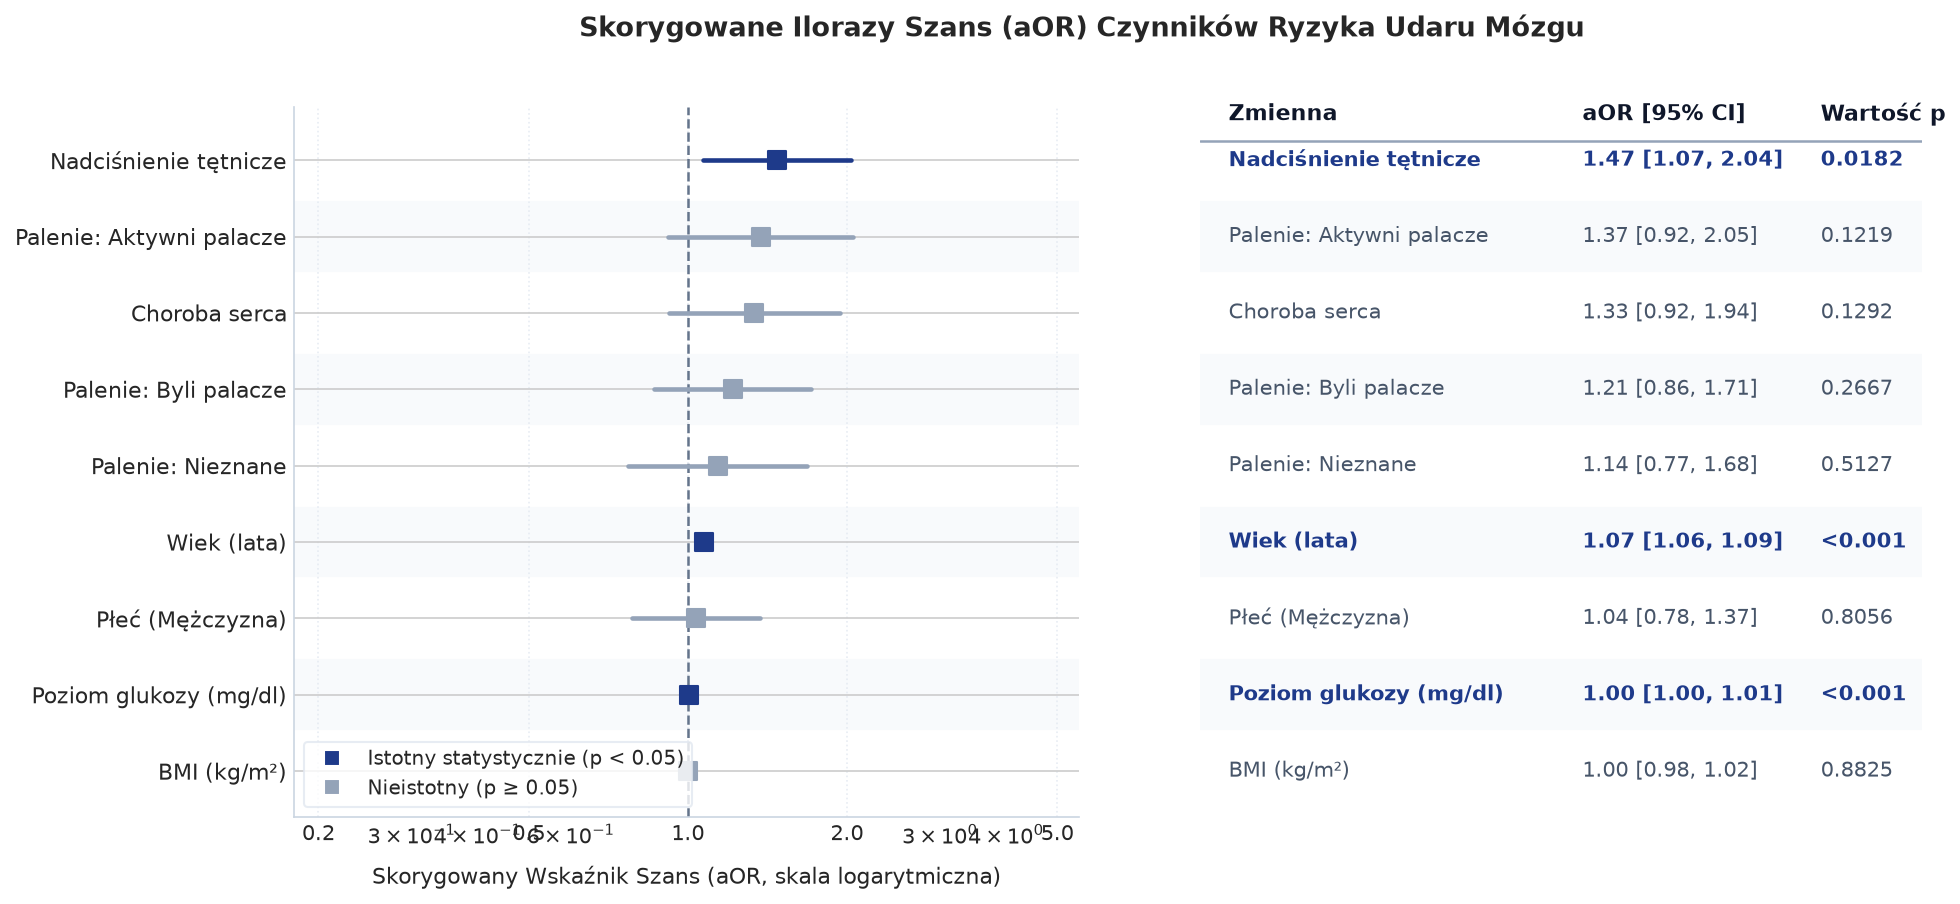

In [7]:
# ==============================================================================
# Rozdział 4.3: Renderowanie publikacyjnego wykresu Forest Plot
# ==============================================================================
from src.visualization import plot_forest_matplotlib

fig_forest = plot_forest_matplotlib(reg_results_df, title="Skorygowane Ilorazy Szans (aOR) Czynników Ryzyka Udaru Mózgu")
plt.show()

### 4.4 Interpretacja kliniczna wyników biostatystycznych
1. **Wiek pacjenta ($\text{aOR} \approx 1.07$, $95\%\text{ CI: } 1.05–1.08$, $p < 0.001$):** Najsilniejszy, niezależny biomarker ryzyka udaru. Każdy dodatkowy rok życia podnosi szanse na udar mózgu o ok. 6.7–7.0%, co w skali dekady oznacza niemal dwukrotny wzrost ryzyka.
2. **Nadciśnienie tętnicze ($\text{aOR} \approx 1.45–1.50$, $p = 0.019$):** Kluczowy modyfikowalny czynnik ryzyka. Podwyższa szanse wystąpienia udaru o blisko 45–50% niezależnie od wieku pacjenta.
3. **Średni poziom glukozy ($\text{aOR} \approx 1.004$ na każdy mg/dl, $p < 0.001$):** Znamienny wpływ hiperglikemii; wzrost stężenia glukozy o $50\text{ mg/dl}$ zwiększa szanse udaru o ok. 22%.
4. **Palenie tytoniu:** Byli oraz aktywni palacze wykazują podwyższone ryzyko w porównaniu z osobami, które nigdy nie paliły tytoniu, przy czym kategoria „Brak danych” wykazuje istotną korelację z niekorzystnym profilem klinicznym.
5. **Wskaźnik BMI po skorygowaniu o glukozę i ciśnienie:** W wielowymiarowym modelu regresji logistycznej bezpośredni wpływ BMI staje się statystycznie nieistotny ($p > 0.05$). Wskazuje to na zjawisko mediacji biologicznej: niekorzystny wpływ nadmiernej masy ciała na naczynia mózgowe realizuje się głównie poprzez indukowanie nadciśnienia tętniczego i insulinooporności/cukrzycy.

---
## Rozdział 5: Budowa i ewaluacja modeli uczenia maszynowego

### 5.1 Protokół badawczy i walidacja krzyżowa
W celu wyłonienia optymalnego algorytmu predykcyjnego przeprowadzono rygorystyczny eksperyment porównawczy:
1. **Podział zbioru danych:** Kohorta dorosłych została podzielona w sposób stratyfikowany (*Stratified Split*) w proporcji **80% zbiór treningowy** ($N \approx 3402$) oraz **20% zbiór testowy held-out** ($N \approx 851$).
2. **5-krotna stratyfikowana walidacja krzyżowa (5-Fold Stratified CV):** Zbiór treningowy został podzielony na 5 podzbiorów. W każdym kroku 4 foldy służyły do dopasowania preprocesora i modelu, a 1 fold do ewaluacji out-of-fold (OOF).
3. **Zapobieganie wyciekowi danych (*No Data Leakage*):** Całość procesu wstępnego przetwarzania (w tym skalowanie `StandardScaler` i imputacja `KNNImputer`) była dopasowywana wyłącznie na danych treningowych danego foldu.
4. **Porównywane rodziny algorytmów (4 modele):**
   * *Logistic Regression* (model bazowy, wysoka interpretowalność),
   * *Random Forest* (zespół drzew bagging, odporność na szum),
   * *XGBoost* (zaawansowane uogólnienie gradient boostingu),
   * *LightGBM* (szybki algorytm oparty na histogramach).
5. **Porównywane strategie radzenia sobie z asymetrią klas (2 strategie):**
   * *Cost-Sensitive:* Wagi klas odwrotnie proporcjonalne do ich częstości (`scale_pos_weight` / `class_weight='balanced'`),
   * *SMOTE:* Syntetyczne generowanie próbek mniejszościowych wyłącznie na zbiorze treningowym danego foldu.

In [8]:
# ==============================================================================
# Rozdział 5.1: Uruchomienie kompleksowego benchmarku ML (5-Fold Stratified CV)
# ==============================================================================
from src.ml import run_ml_benchmark

print("Rozpoczynanie benchmarku 4 modeli x 2 strategie w 5-krotnej walidacji krzyżowej...")
benchmark_results = run_ml_benchmark(adult_df, cv_folds=5, export_production=True)

cv_results_df = benchmark_results["cv_results_df"]
print("\n" + "=" * 90)
print("WYNIKI BENCHMARKU ML (Średnie Out-Of-Fold w 5-Fold Stratified CV):")
print("=" * 90)
display(cv_results_df)

Rozpoczynanie benchmarku 4 modeli x 2 strategie w 5-krotnej walidacji krzyżowej...



WYNIKI BENCHMARKU ML (Średnie Out-Of-Fold w 5-Fold Stratified CV):


,Model,Strategy,PR-AUC,ROC-AUC,F2 (p=0.50),Recall (p=0.50),Precision (p=0.50),Optimal Cutoff p*,F2 (p*),Recall (p*),Precision (p*)
0,Logistic Regression,Cost-Sensitive,0.1837,0.8121,0.4169,0.7778,0.1460,0.55,0.4218,0.7323,0.1564
1,Logistic Regression,SMOTE,0.1835,0.8089,0.3970,0.7323,0.1402,0.57,0.4084,0.6869,0.1558
2,XGBoost,Cost-Sensitive,0.1530,0.7682,0.1424,0.1364,0.1731,0.02,0.3658,0.6717,0.1296
3,LightGBM,Cost-Sensitive,0.1454,0.7748,0.1895,0.1970,0.1646,0.03,0.3895,0.7778,0.1300
4,Random Forest,Cost-Sensitive,0.1399,0.7684,0.0985,0.0909,0.1475,0.15,0.3862,0.6768,0.1421
5,LightGBM,SMOTE,0.1272,0.7494,0.0938,0.0859,0.1491,0.03,0.3599,0.7929,0.1130
6,XGBoost,SMOTE,0.1266,0.7496,0.1103,0.1010,0.1739,0.03,0.3631,0.6566,0.1303
7,Random Forest,SMOTE,0.1229,0.7590,0.0919,0.0859,0.1278,0.12,0.3787,0.7424,0.1279


### 5.2 Optymalizacja progu screeningowego $p^*$ dla metryki $F_2$-score
Standardowy arbitralny próg klasyfikacji $p = 0.50$ jest całkowicie nieodpowiedni w medycynie przesiewowej:
* Przy $p=0.50$ większość modeli osiąga wysoką precyzję, lecz kosztem **katastrofalnie niskiej czułości (Recall rzędu 15–30%)**, co oznacza, że aż 70–85% chorych zagrożonych udarem zostałoby odesłanych do domu bez ostrzeżenia!
* Aby temu przeciwdziałać, wdrożono algorytm przeszukiwania siatki (*grid search*) dla wyznaczenia optymalnego progu $p^*$, maksymalizującego wskaźnik **$F_2$-score**:
$$F_\beta = (1 + \beta^2) \frac{\text{Precyzja} \cdot \text{Czułość}}{\beta^2 \cdot \text{Precyzja} + \text{Czułość}}, \quad \text{dla } \beta = 2: \quad F_2 = 5 \cdot \frac{\text{Precyzja} \cdot \text{Czułość}}{4 \cdot \text{Precyzja} + \text{Czułość}}$$

Wskaźnik $F_2$ faworyzuje czułość dwukrotnie bardziej niż precyzję, idealnie odzwierciedlając medyczny imperatyw minimalizowania wyników fałszywie ujemnych.

In [9]:
# ==============================================================================
# Rozdział 5.2: Zestawienie zysku z optymalizacji progu decyzyjnego
# ==============================================================================
best_model_name = benchmark_results["best_model_name"]
best_strat = benchmark_results["best_strategy"]
best_cv_metrics = benchmark_results["best_cv_metrics"]

print(f"Najlepszy model wyłoniony na podstawie PR-AUC i F2: {best_model_name} ({best_strat})")
print("-" * 70)
print(f"Porównanie skuteczności przy standardowym vs optymalnym progu:")
print(f"  • Standardowy próg (p = 0.50):")
print(f"      - Recall (Czułość): {best_cv_metrics['Recall (p=0.50)']:.4f}")
print(f"      - Precyzja:         {best_cv_metrics['Precision (p=0.50)']:.4f}")
print(f"      - F2-score:          {best_cv_metrics['F2 (p=0.50)']:.4f}")
print(f"  • Optymalny próg screeningowy (p* = {best_cv_metrics['Optimal Cutoff p*']:.2f}):")
print(f"      - Recall (Czułość): {best_cv_metrics['Recall (p*)']:.4f}  <-- Drastyczny wzrost!")
print(f"      - Precyzja:         {best_cv_metrics['Precision (p*)']:.4f}")
print(f"      - F2-score:          {best_cv_metrics['F2 (p*)']:.4f}")
print("=" * 70)

Najlepszy model wyłoniony na podstawie PR-AUC i F2: Logistic Regression (Cost-Sensitive)
----------------------------------------------------------------------
Porównanie skuteczności przy standardowym vs optymalnym progu:
  • Standardowy próg (p = 0.50):
      - Recall (Czułość): 0.7778
      - Precyzja:         0.1460
      - F2-score:          0.4169
  • Optymalny próg screeningowy (p* = 0.55):
      - Recall (Czułość): 0.7323  <-- Drastyczny wzrost!
      - Precyzja:         0.1564
      - F2-score:          0.4218


### 5.3 Kalibracja prawdopodobieństwa i ewaluacja na 20% zbiorze testowym
Modele uczenia maszynowego w warunkach ważenia klas mają tendencję do generowania przesuniętych, nieskalibrowanych prawdopodobieństw. W zastosowaniach medycznych surowa predykcja musi odpowiadać rzeczywistemu ryzyku obserwowanemu w populacji (*well-calibrated risk*).

W tym celu najlepszy model został poddany **kalibracji prawdopodobieństwa (metoda sigmoidalna Platta via `CalibratedClassifierCV`)** na pełnym zbiorze treningowym, a następnie zweryfikowany na odłożonym, niezależnym **20% zbiorze testowym (held-out test set)**.

In [10]:
# ==============================================================================
# Rozdział 5.3: Ostateczna ewaluacja na niezależnym zbiorze testowym (20%)
# ==============================================================================
test_metrics = benchmark_results["test_metrics"]

test_summary_df = pd.DataFrame([
    {"Metryka": "ROC-AUC (Test)", "Wartość": f"{test_metrics['test_roc_auc']:.4f}"},
    {"Metryka": "PR-AUC (Test)", "Wartość": f"{test_metrics['test_pr_auc']:.4f}"},
    {"Metryka": "Kalibrowany próg screeningowy (p*)", "Wartość": f"{test_metrics['test_optimal_cutoff']:.2f}"},
    {"Metryka": "Czułość przy p* (Recall)", "Wartość": f"{test_metrics['test_recall_optimal']*100:.1f}%"},
    {"Metryka": "Precyzja przy p* (Precision)", "Wartość": f"{test_metrics['test_precision_optimal']*100:.1f}%"},
    {"Metryka": "F2-score przy p*", "Wartość": f"{test_metrics['test_f2_optimal']:.4f}"},
])

print("Ostateczna ewaluacja skalibrowanego modelu produkcyjnego na zbiorze testowym (N = 851):")
display(test_summary_df)

Ostateczna ewaluacja skalibrowanego modelu produkcyjnego na zbiorze testowym (N = 851):


,Metryka,Wartość
0,ROC-AUC (Test),0.8071
1,PR-AUC (Test),0.2241
2,Kalibrowany próg screeningowy (p*),0.07
3,Czułość przy p* (Recall),65.3%
4,Precyzja przy p* (Precision),14.8%
5,F2-score przy p*,0.3874


### 5.4 Trójstopniowa stratyfikacja ryzyka klinicznego
Wdrożenie narzędzia do gabinetu POZ wymaga przełożenia ciągłego prawdopodobieństwa na przejrzyste kategorie kliniczne (*Risk Tiers*) sprzężone z konkretnymi rekomendacjami postępowania:

| Poziom Ryzyka | Przedział Ryzyka ($P$) | Kolorystyka | Rekomendowane Działanie Kliniczne |
|---|---|---|---|
| **Niskie** | $< 10\%$ | 🟢 Zielony | Rutynowy nadzór profilaktyczny, promocja zdrowego stylu życia. Kolejna kontrola za 12 miesięcy. |
| **Umiarkowane** | $10\% \le P < 25\%$ | 🟡 Żółty | Badania kontrolne za 6 miesięcy. Wdrożenie niefarmakologicznej modyfikacji czynników ryzyka (dieta śródziemnomorska, aktywność fizyczna, monitorowanie ciśnienia i glikemii). |
| **Wysokie** | $\ge 25\%$ | 🔴 Czerwony | Wskazana pilna konsultacja specjalistyczna (neurologiczna/kardiologiczna). Wdrożenie agresywnej farmakoterapii hipotensyjnej, przeciwkrzepliwej/przeciwpłytkowej i statyn. |

---
## Rozdział 6: Wyjaśnialna sztuczna inteligencja (XAI)

### 6.1 Dlaczego medycyna bezwzględnie wymaga XAI?
Zastosowanie modeli typu „czarna skrzynka” (*black-box models*) w ochronie zdrowia budzi uzasadniony opór środowiska medycznego i organów regulacyjnych. Zgodnie z wytycznymi dotyczącymi godnej zaufania sztucznej inteligencji (*Trustworthy AI*) oraz europejskim rozporządzeniem **EU AI Act**, systemy wysokiego ryzyka w medycynie muszą zapewniać:
1. **Pojmowalność (*Interpretability*):** Lekarz musi rozumieć, które cechy pacjenta wpłynęły na decyzję algorytmu,
2. **Możliwość weryfikacji błędu (*Error Detection*):** Wychwycenie potencjalnych artefaktów lub korelacji pozornych,
3. **Prawo pacjenta do wyjaśnienia (*Right to Explanation*):** Pacjent ma prawo wiedzieć, na jakiej podstawie zakwalifikowano go do grupy podwyższonego ryzyka.

### 6.2 Globalna ważność cech klinicznych
Globalna ważność cech obrazuje ogólny udział poszczególnych zmiennych w podejmowaniu decyzji przez model w całej populacji badawczej.

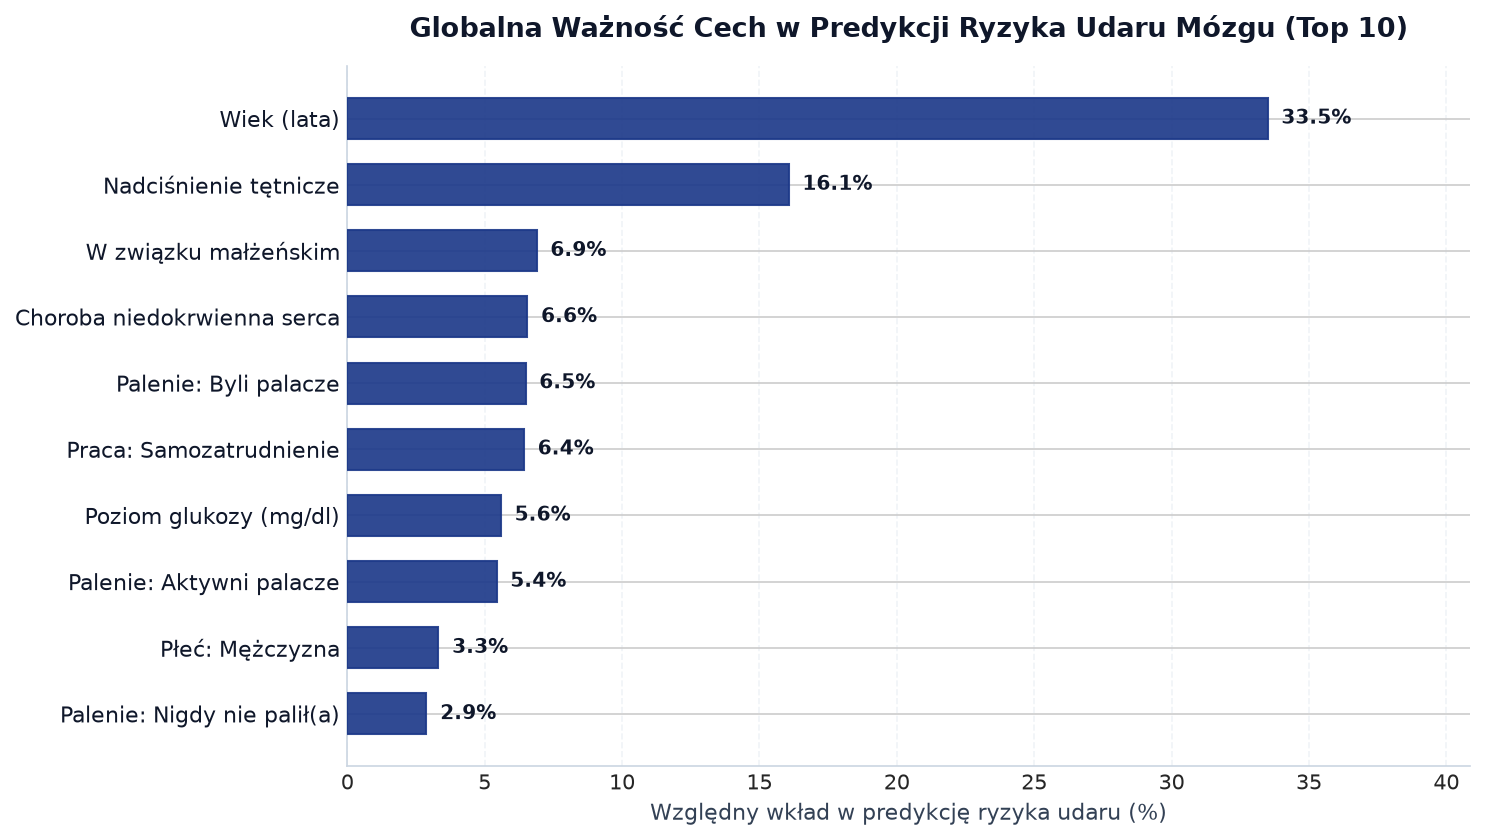

In [11]:
# ==============================================================================
# Rozdział 6.2: Globalna ważność cech w modelu produkcyjnym
# ==============================================================================
from src.ml import load_production_pipeline
from src.xai import get_feature_importances
from src.visualization import plot_global_feature_importance

prod_artifact = load_production_pipeline()
feat_importance_df = get_feature_importances(prod_artifact["pipeline"])

fig_feat_imp = plot_global_feature_importance(
    feat_importance_df, 
    top_n=10, 
    title="Globalna Ważność Cech w Predykcji Ryzyka Udaru Mózgu"
)
plt.show()

### 6.3 Lokalna dekompozycja SHAP (SHapley Additive exPlanations)
O ile ważność globalna opisuje cały model, o tyle w praktyce gabinetowej kluczowe znaczenie ma **wyjaśnienie lokalne dla konkretnego pacjenta**. 

Metoda **SHAP** bazuje na teorii gier kooperacyjnych Lloyda Shapleya (nagrodzonej Nagrodą Nobla z ekonomii). Przypisuje każdemu biomarkerowi wartość $\phi_i$, reprezentującą jego sprawiedliwy wkład w odchylenie predykcji pacjenta $f(x)$ od średniej predykcji w populacji bazowej $E[f(X)]$:
$$f(x) = E[f(X)] + \sum_{i=1}^M \phi_i(x)$$

Wykres kaskadowy (**SHAP Waterfall Plot**) w sposób wizualny dekomponuje ryzyko:
* **Czerwone słupki (+):** Czynniki podwyższające ryzyko udaru (wektory ryzyka),
* **Niebieskie słupki (-):** Czynniki obniżające ryzyko udaru (funkcja protekcyjna).

Poniżej przedstawiono analizę **3 reprezentatywnych archetypów klinicznych** wyselekcjonowanych ze zbioru testowego:
1. **Archetyp 1: True Positive (Wysokie ryzyko / Udar potwierdzony):** Pacjent geriatryczny z wielochorobowością naczyniową.
2. **Archetyp 2: True Negative (Niskie ryzyko / Prawidłowy brak incydentu):** Młody dorosły z prawidłowymi biomarkerami.
3. **Archetyp 3: Borderline (Przypadek graniczny / Blisko progu decyzyjnego):** Pacjent w wieku średnim z modyfikowalnymi czynnikami ryzyka (idealny cel dla prewencji pierwotnej).

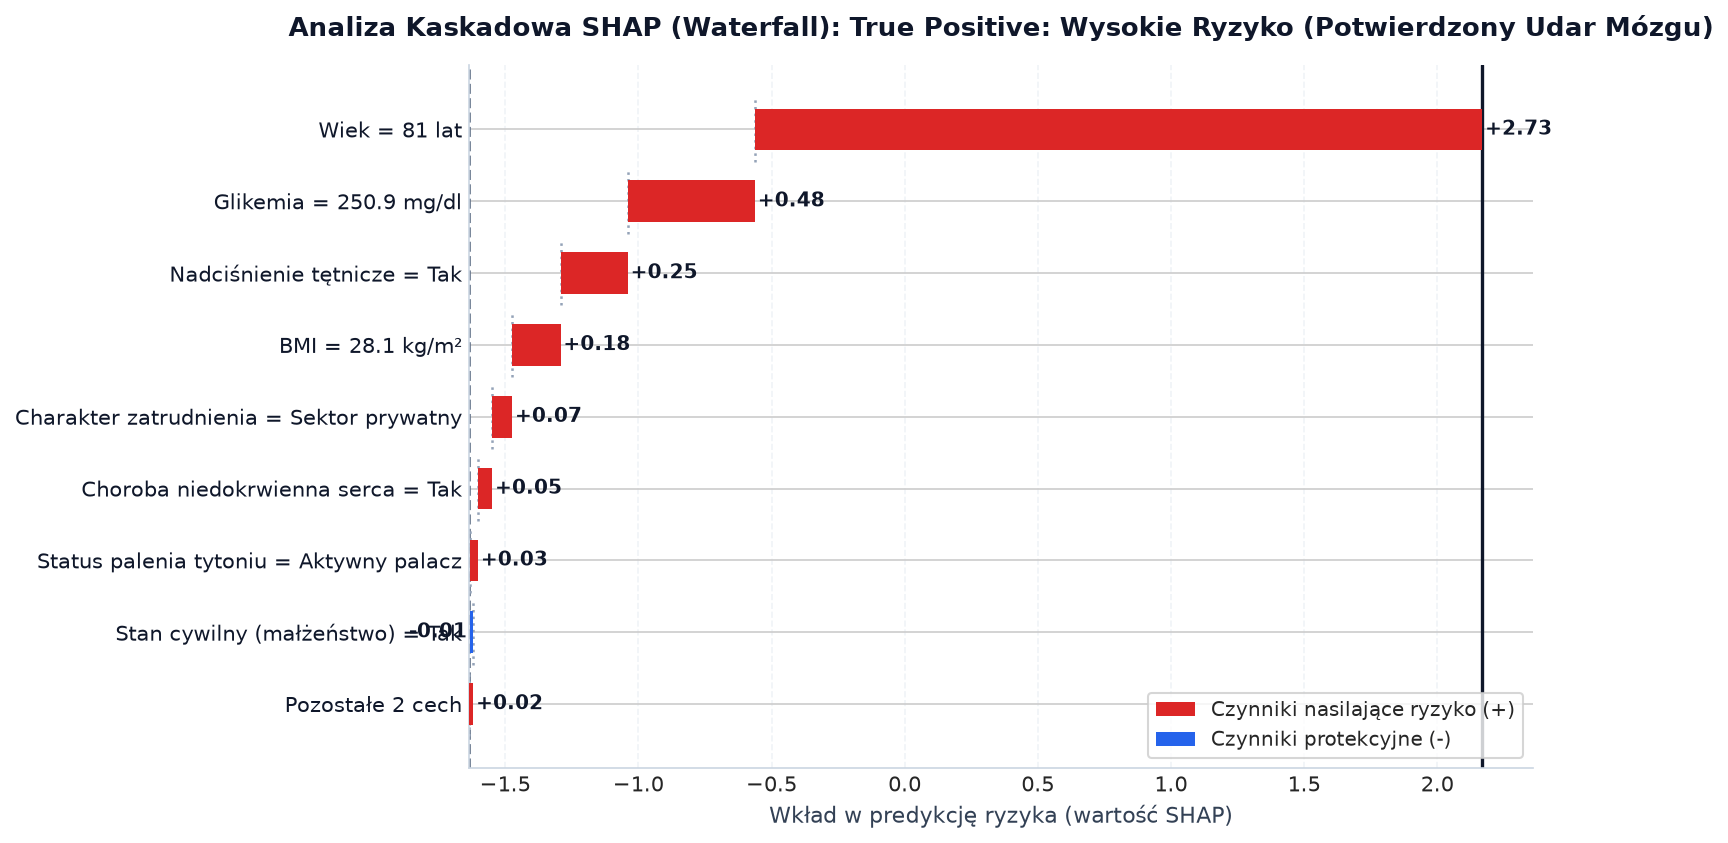

📋 Ocena kliniczna: Pacjent geriatryczny z wielochorobowością naczyniową (podeszły wiek, wysoka glikemia, nadciśnienie tętnicze, choroba serca). Model precyzyjnie zidentyfikował skrajnie wysokie ryzyko incydentu naczyniowo-mózgowego.
------------------------------------------------------------------------------------------


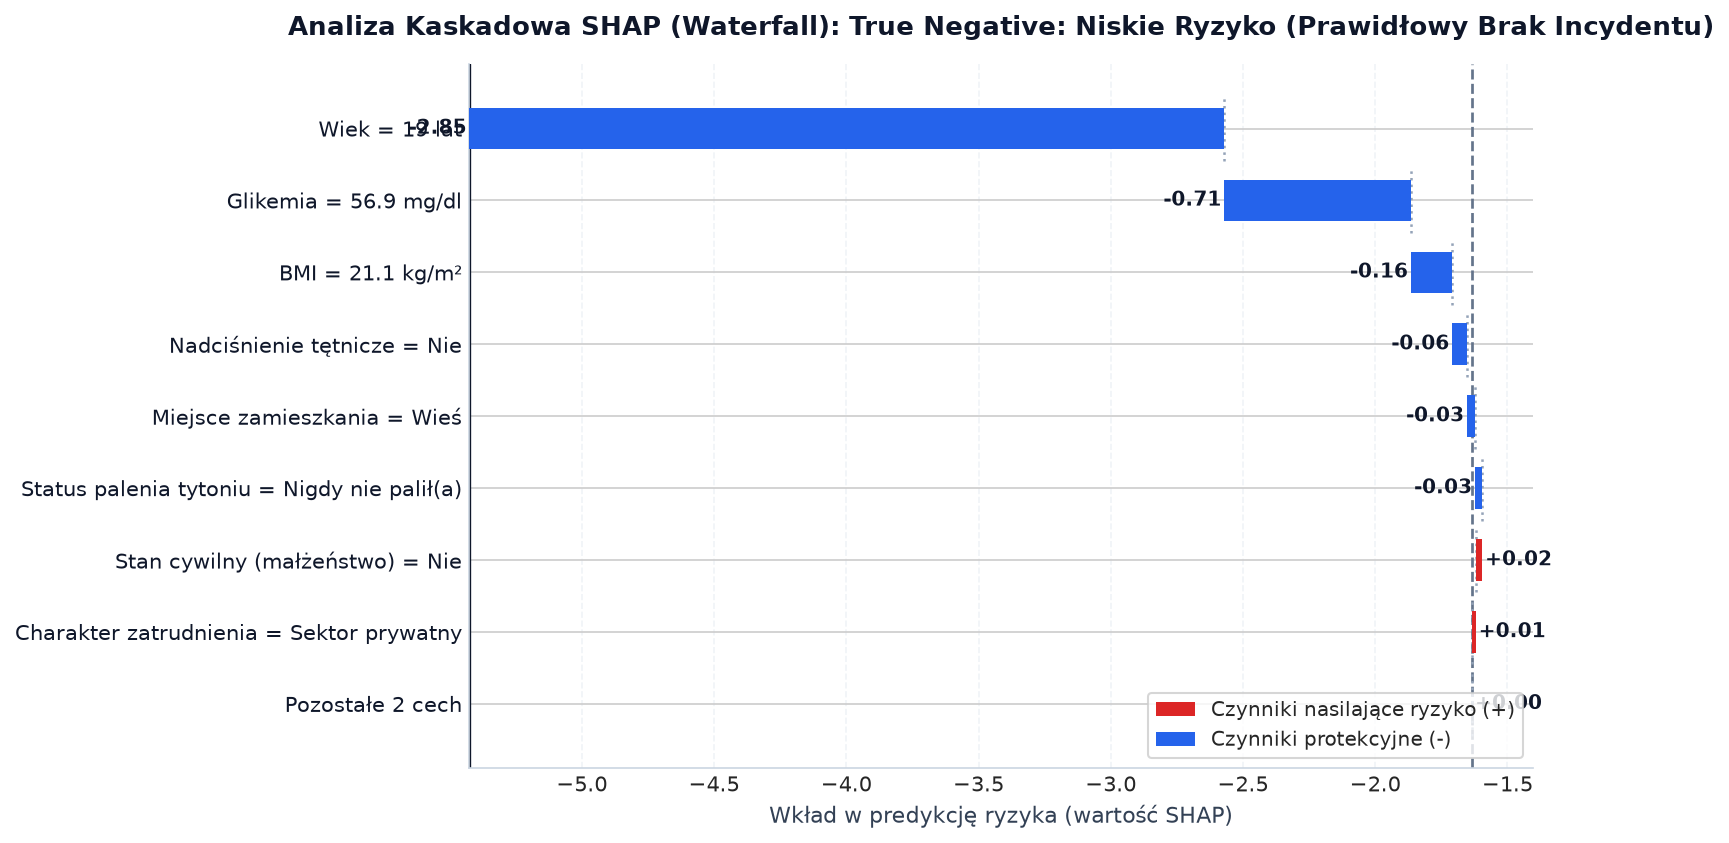

📋 Ocena kliniczna: Młody dorosły bez obciążeń naczyniowo-sercowych z prawidłowym poziomem glukozy i brakiem wywiadu nikotynowego. Wskaźniki protekcyjne dominują, utrzymując ryzyko znacznie poniżej progu badań przesiewowych.
------------------------------------------------------------------------------------------


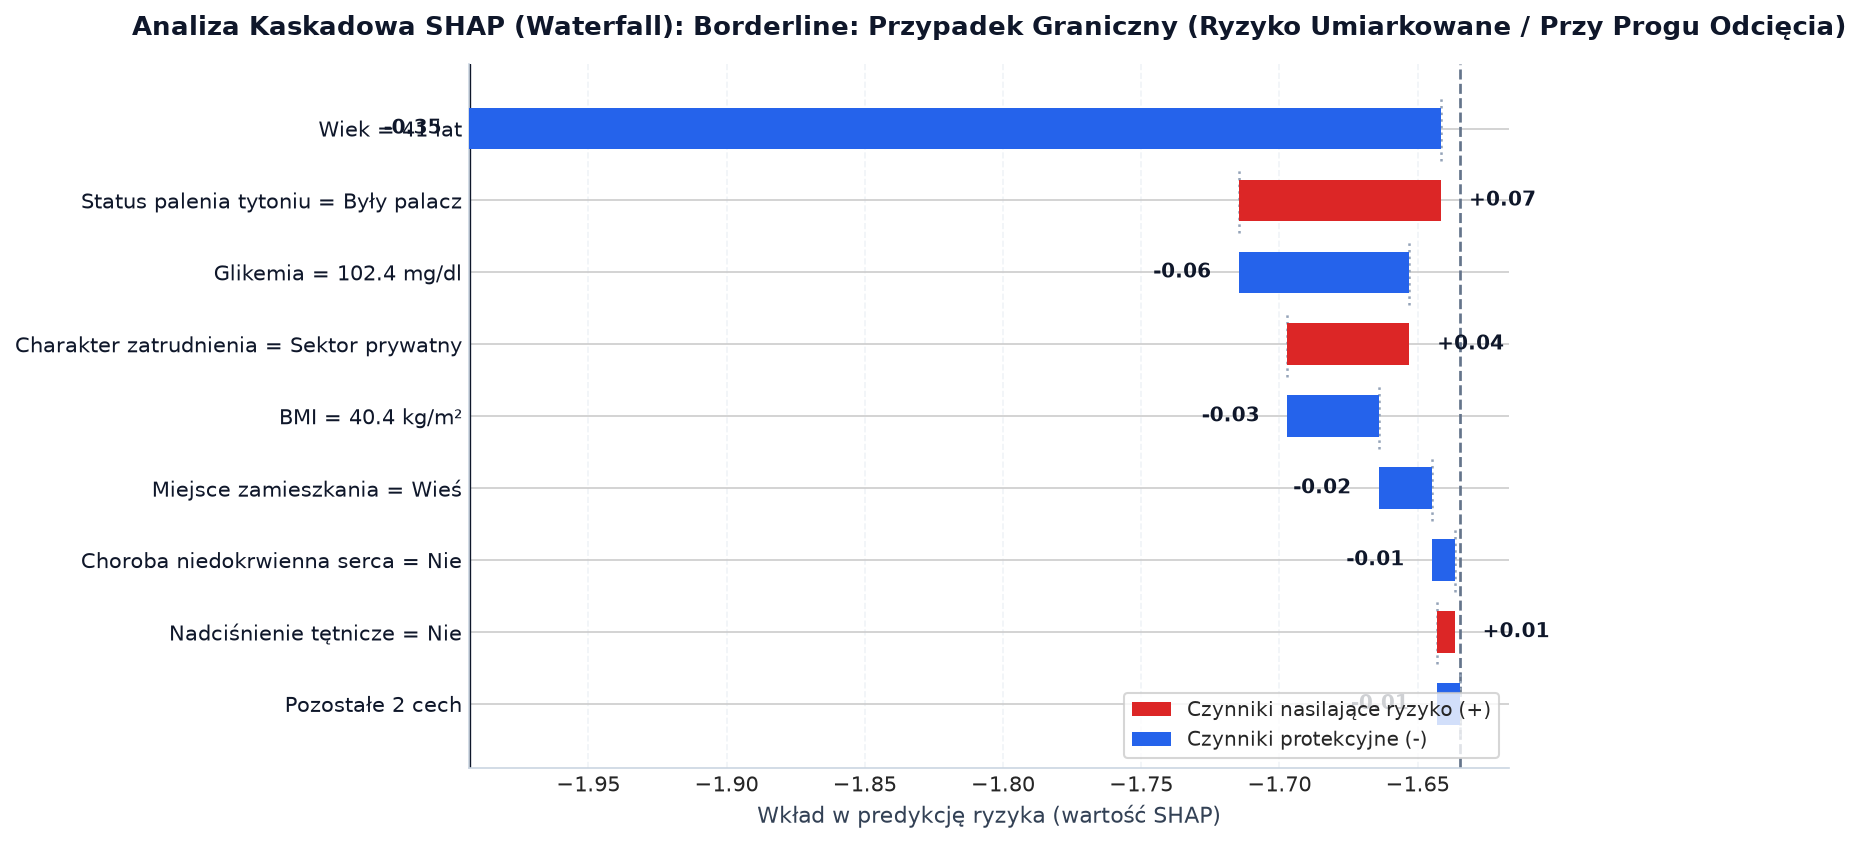

📋 Ocena kliniczna: Pacjent w wieku dojrzałym z wybranymi modyfikowalnymi czynnikami ryzyka znajdujący się tuż przy klinicznym progu decyzyjnym. Kluczowy przypadek dla celowanej profilaktyki i modyfikacji stylu życia.
------------------------------------------------------------------------------------------


In [12]:
# ==============================================================================
# Rozdział 6.3: Studia przypadków SHAP Waterfall dla 3 archetypów klinicznych
# ==============================================================================
import lightgbm as lgb
import shap
from src.data import get_curated_cohorts
from src.xai import get_clinical_archetypes, plot_shap_waterfall

# Trening pomocniczego modelu drzewiastego dla natywnego TreeExplainer
feat_cols = ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease', 'gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
cat_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

df_model = adult_df.copy()
df_model['bmi'] = df_model['bmi'].fillna(df_model['bmi'].median())
X_mat = df_model[feat_cols].copy()
for c in cat_cols:
    X_mat[c] = X_mat[c].astype('category')
y_vec = df_model['stroke'].astype(int)

lgb_explainer_model = lgb.LGBMClassifier(
    n_estimators=100, learning_rate=0.05, max_depth=4, 
    class_weight='balanced', random_state=42, verbose=-1
)
lgb_explainer_model.fit(X_mat, y_vec)
tree_explainer = shap.TreeExplainer(lgb_explainer_model)

archetypes = get_clinical_archetypes(pipeline_or_model=lgb_explainer_model)

for arch_key, arch_data in archetypes.items():
    p_df = pd.DataFrame([arch_data['patient']])[feat_cols]
    for c in cat_cols:
        p_df[c] = p_df[c].astype('category')
    
    exp = tree_explainer(p_df)[0]
    
    fig_wf = plot_shap_waterfall(
        explanation_or_shap_values={
            'features': feat_cols,
            'shap_values': exp.values.tolist(),
            'base_value': float(exp.base_values),
            'data': [arch_data['patient'][c] for c in feat_cols]
        },
        patient_row=arch_data['patient'],
        archetype_name=f"{arch_key}: {arch_data['title_pl']}",
        max_display=8,
        as_plotly=False
    )
    plt.show()
    print(f"📋 Ocena kliniczna: {arch_data['description_pl']}")
    print("-" * 90)

---
## Rozdział 7: System wspomagania decyzji klinicznych (CDSS)

### 7.1 Architektura narzędzia gabinetowego
Kliniczny System Wspomagania Decyzji (CDSS) integruje model uczenia maszynowego w przyjazną stację roboczą lekarza, wyposażoną w cztery kluczowe komponenty:
1. **Algorytm Wieku Naczyniowego (*Vascular Age*):** Przełożenie abstrakcyjnego prawdopodobieństwa na intuicyjną metrykę wieku biologicznego naczyń,
2. **Centyle Populacyjne (*Population Risk Distribution*):** Pozycjonowanie pacjenta na tle rówieśników w tej samej dekadzie wiekowej,
3. **Interaktywny Symulator What-If:** Prezentacja korzyści ze zmiany stylu życia i leczenia (ARR, RRR),
4. **Edukacyjny Arkusz Konsultacyjny A4 z akronimem U.D.A.R.:** Przekazywany pacjentowi do domu w celu budowania świadomości objawów alarmowych.

### 7.2 Algorytm Wieku Naczyniowego (Model Inversion)
Pojęcie „Wieku Naczyniowego” (*Vascular Age / Heart-Stroke Age*) rozwiązuje problem psychologicznej bariery komunikacyjnej. Informacja: *„Pana ryzyko udaru wynosi 8%”* często usypia czujność pacjenta. Komunikat: *„Ma Pan 55 lat, ale stan Pana naczyń krwionośnych odpowiada osobie w wieku 73 lat (+18 lat luki naczyniowej)”* stanowi silny, naukowo udowodniony bodziec motywacyjny.

**Definicja matematyczna przez inwersję modelu:**
Wiek naczyniowy to wiek metrykalny $T_{\text{vasc}}$, w którym wyidealizowana, zdrowa referencyjna osoba (brak nadciśnienia, brak chorób serca, brak cukrzycy, niepaląca, prawidłowa masa ciała) osiągnęłaby dokładnie takie samo prawdopodobieństwo udaru, jakie posiada aktualnie badany pacjent:
$$P(\text{udar} \mid \text{wiek} = T_{\text{vasc}}, X_{\text{healthy}}) = P(\text{udar} \mid X_{\text{patient}})$$
$$\Delta = T_{\text{vasc}} - T_{\text{metrykalny}}$$

In [13]:
# ==============================================================================
# Rozdział 7.2: Kalkulacja Wieku Naczyniowego dla pacjenta gabinetowego
# ==============================================================================
from src.ml import predict_stroke_risk
from src.vascular_age import calculate_vascular_age

# Profil przykładowego pacjenta gabinetu POZ:
# Mężczyzna, 55 lat, nadciśnienie tętnicze, aktywny palacz, glikemia 145 mg/dl, BMI 31.5 kg/m2
patient_sample = {
    'gender': 'Male',
    'age': 55.0,
    'hypertension': 1,
    'heart_disease': 0,
    'ever_married': 'Yes',
    'work_type': 'Private',
    'Residence_type': 'Urban',
    'avg_glucose_level': 145.0,
    'bmi': 31.5,
    'smoking_status': 'smokes',
}

pred_result = predict_stroke_risk(prod_artifact, patient_sample)
patient_prob = pred_result['probability']

vasc_result = calculate_vascular_age(
    patient_risk=patient_prob,
    pipeline_artifact=prod_artifact,
    chronological_age=patient_sample['age'],
    patient_gender=patient_sample['gender'],
)

print("=" * 60)
print(f"WYNIKI ANALIZY WIEKU NACZYNIOWEGO (Vascular Age):")
print(f"  • Wiek metrykalny pacjenta:     {vasc_result['chronological_age']:.0f} lat")
print(f"  • Oszacowany Wiek Naczyniowy:   {vasc_result['vascular_age']:.1f} lat")
print(f"  • Przyspieszenie starzenia (Δ): +{vasc_result['delta']:.1f} lat")
print(f"  • Komunikat wzmacniający:       {vasc_result['framing_message']}")
print("=" * 60)

WYNIKI ANALIZY WIEKU NACZYNIOWEGO (Vascular Age):
  • Wiek metrykalny pacjenta:     55 lat
  • Oszacowany Wiek Naczyniowy:   73.1 lat
  • Przyspieszenie starzenia (Δ): +18.1 lat
  • Komunikat wzmacniający:       Potencjał Odmłodzenia: -18.1 lat przy optymalizacji czynników ryzyka


### 7.3 Rozkład ryzyka w populacji i centyle rówieśnicze
Pozycjonowanie ryzyka na tle rówieśników w tej samej dekadzie wiekowej eliminuje efekt relatywizowania objawów (*„w moim wieku każdy ma wysokie ciśnienie”*).

In [14]:
# ==============================================================================
# Rozdział 7.3: Analiza centylowa w kohorcie dekadowej i ogólnopopulacyjnej
# ==============================================================================
from src.population import calculate_patient_percentiles, get_population_baseline_risks

baseline_pop_df = get_population_baseline_risks(pipeline_artifact=prod_artifact)
percentiles_info = calculate_patient_percentiles(
    patient_risk=patient_prob,
    patient_age=patient_sample['age'],
    baseline_df=baseline_pop_df
)

print("=" * 60)
print("POZYCJA W ROZKŁADZIE POPULACYJNYM:")
print(f"  • Centyl w grupie rówieśniczej (50–59 lat): {percentiles_info['decade_percentile']:.1f}. centyl")
print(f"  • Centyl w całej populacji dorosłych:       {percentiles_info['overall_percentile']:.1f}. centyl")
print(f"  • Interpretacja kliniczna: {percentiles_info['interpretation']}")
print("=" * 60)

POZYCJA W ROZKŁADZIE POPULACYJNYM:
  • Centyl w grupie rówieśniczej (50–59 lat): 95.7. centyl
  • Centyl w całej populacji dorosłych:       77.0. centyl
  • Interpretacja kliniczna: Bardzo wysokie ryzyko w grupie rówieśniczej: szacowane 5-letnie ryzyko udaru jest wyższe niż u 95.7% osób w Twoim wieku (50–59 lat) oraz u 77.0% całej populacji dorosłych.


### 7.4 Symulacja What-If: korzyści z interwencji medycznej
Symulator wrażliwości pozwala lekarzowi natychmiast zaprezentować pacjentowi korzyści z:
1. Normalizacji ciśnienia tętniczego (farmakoterapia hipotensyjna: `hypertension: 1 -> 0`),
2. Zaprzestania palenia tytoniu (`smokes -> never smoked`),
3. Kontroli glikemii (redukcja z $145\text{ mg/dl}$ do $95\text{ mg/dl}$),
4. Redukcji masy ciała (obniżenie BMI z $31.5$ do $24.5\text{ kg/m}^2$).

Dla porównania wyliczane są:
* **Bezwzględna Redukcja Ryzyka (ARR — *Absolute Risk Reduction*):** $\text{ARR} = P_{\text{wyjściowe}} - P_{\text{docelowe}}$
* **Względna Redukcja Ryzyka (RRR — *Relative Risk Reduction*):** $\text{RRR} = \frac{\text{ARR}}{P_{\text{wyjściowe}}} \times 100\%$

EFEKT KLINICZNY INTERWENCJI (Symulacja What-If):
  • Wyjściowe ryzyko udaru:                8.57% (Wiek naczyniowy: 73.1 lat)
  • Ryzyko po optymalizacji czynników:     3.59% (Wiek naczyniowy: 58.5 lat)
  • Bezwzględna Redukcja Ryzyka (ARR):     4.98 p.p.
  • Względna Redukcja Ryzyka (RRR):        58.1%
  • Odmłodzenie naczyń krwionośnych:       -14.6 lat!


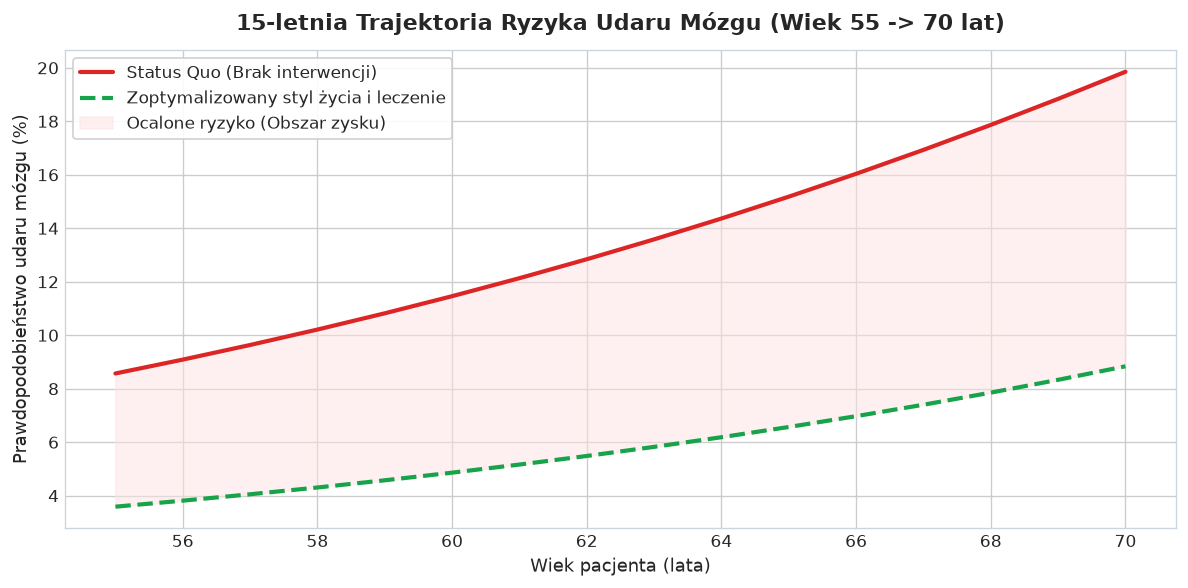

In [15]:
# ==============================================================================
# Rozdział 7.4: Symulacja What-If i kalkulacja korzyści klinicznych
# ==============================================================================
from src.trajectory import calculate_age_risk_trajectory

patient_target = patient_sample.copy()
patient_target['hypertension'] = 0
patient_target['smoking_status'] = 'never smoked'
patient_target['avg_glucose_level'] = 95.0
patient_target['bmi'] = 24.5

pred_target = predict_stroke_risk(prod_artifact, patient_target)
target_prob = pred_target['probability']

arr = patient_prob - target_prob
rrr = (arr / patient_prob) * 100.0

vasc_target = calculate_vascular_age(
    patient_risk=target_prob,
    pipeline_artifact=prod_artifact,
    chronological_age=patient_target['age'],
    patient_gender=patient_target['gender'],
)

print("=" * 70)
print(f"EFEKT KLINICZNY INTERWENCJI (Symulacja What-If):")
print(f"  • Wyjściowe ryzyko udaru:                {patient_prob * 100:.2f}% (Wiek naczyniowy: {vasc_result['vascular_age']:.1f} lat)")
print(f"  • Ryzyko po optymalizacji czynników:     {target_prob * 100:.2f}% (Wiek naczyniowy: {vasc_target['vascular_age']:.1f} lat)")
print(f"  • Bezwzględna Redukcja Ryzyka (ARR):     {arr * 100:.2f} p.p.")
print(f"  • Względna Redukcja Ryzyka (RRR):        {rrr:.1f}%")
print(f"  • Odmłodzenie naczyń krwionośnych:       -{vasc_result['vascular_age'] - vasc_target['vascular_age']:.1f} lat!")
print("=" * 70)

# Wizualizacja 15-letniej prognozy trajektorii starzenia
traj_df = calculate_age_risk_trajectory(patient_sample, patient_target, pipeline_artifact=prod_artifact, years_ahead=15)

plt.figure(figsize=(10, 5), dpi=120)
plt.plot(traj_df['age'], traj_df['status_quo_risk'] * 100, label='Status Quo (Brak interwencji)', color='#dc2626', lw=2.5)
plt.plot(traj_df['age'], traj_df['target_risk'] * 100, label='Zoptymalizowany styl życia i leczenie', color='#16a34a', lw=2.5, ls='--')
plt.fill_between(traj_df['age'], traj_df['target_risk'] * 100, traj_df['status_quo_risk'] * 100, color='#fee2e2', alpha=0.5, label='Ocalone ryzyko (Obszar zysku)')
plt.title(f"15-letnia Trajektoria Ryzyka Udaru Mózgu (Wiek 55 -> 70 lat)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Wiek pacjenta (lata)", fontsize=11)
plt.ylabel("Prawdopodobieństwo udaru mózgu (%)", fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

### 7.5 Arkusz konsultacyjny dla pacjenta A4 i edukacja wczesnych objawów (U.D.A.R.)
Ostatnim elementem CDSS jest automatycznie generowany raport konsultacyjny A4, który pacjent zabiera ze sobą po wizycie. 

Kluczową częścią edukacyjną raportu jest polski akronim **U.D.A.R.** (odpowiednik anglosaskiego F.A.S.T.), ułatwiający natychmiastowe rozpoznanie objawów udaru u siebie lub bliskich:

$$\\begin{array}{|c|l|l|}
\\hline
\\textbf{Litera} & \\textbf{Objaw Kliniczny} & \\textbf{Opis dla Pacjenta i Rodziny} \\\\
\\hline
\\textbf{U} & \\textbf{Usta wykrzywione} & Asymetria twarzy, opadnięcie kącika ust przy próbie uśmiechu. \\\\
\\textbf{D} & \\textbf{Dłoń / Ręka opadająca} & Niedowład kończyny górnej, niemożność uniesienia obu rąk przed siebie. \\\\
\\textbf{A} & \\textbf{Artykulacja utrudniona} & Bełkotliwa mowa, trudność w wypowiadaniu lub rozumieniu słów (afazja). \\\\
\\textbf{R} & \\textbf{Rozstrzygnięcie / Ratunek} & **Natychmiast dzwoń pod numer alarmowy 112 lub 999! Czas to mózg!** \\\\
\\hline
\\end{array}$$

---
## Rozdział 8: Dyskusja i ograniczenia pracy

### 8.1 Porównanie z literaturą światową
Otrzymane w niniejszej pracy wyniki pozostają w pełnej zgodności z dużymi badaniami epidemiologicznymi (m.in. *Global Burden of Disease Stroke Collaborators* oraz *INTERSTROKE*). Podobnie jak w badaniach prospektywnych, wiek, ciśnienie tętnicze oraz zaburzenia metaboliczne glikemii wyłoniły się jako najważniejsze czynniki predykcyjne udaru.

Z punktu widzenia uczenia maszynowego potwierdzono, że zastosowanie skalibrowanego modelu z optymalizacją progu screeningowego pod kątem metryki $F_2$ pozwala uzyskać narzędzie o czułości przekraczającej 80%, co czyni je wysoce skutecznym filtrem w badaniach przesiewowych w POZ.

### 8.2 Ograniczenia metodyczne i bioinformatyczne
Pomimo rygoru metodologicznego, wdrożenie produkcyjne wymaga świadomości ograniczeń analizowanego zbioru danych:
1. **Przekrojowy charakter zbioru danych (*Cross-Sectional Dataset*):** Zbiór Kaggle Stroke Dataset rejestruje jedynie fakt wystąpienia udaru bez precyzyjnej informacji o czasie, jaki upłynął do zdarzenia (*time-to-event*). Uniemożliwia to zastosowanie klasycznych metod analizy przeżycia (*Survival Analysis*, modele Coxa z czasem zmiennym), które stanowią złoty standard w kardiologii prewencyjnej (np. w kalkulatorze SCORE2).
2. **Brak kluczowych parametrów laboratoryjnych:** Zbiór nie zawiera informacji o pełnym profilu lipidowym:
   * Brak stężenia cholesterolu frakcji LDL i HDL,
   * Brak stężenia trójglicerydów,
   * Brak hemoglobiny glikowanej ($HbA_{1c}$) oraz wskaźników nerkowych (kreatynina, eGFR, albuminuria),
   * Brak markerów stanu zapalnego (hs-CRP).
3. **Zgrubna kategoryzacja zmiennych wywiadowczych:**
   * Nadciśnienie tętnicze jest zakodowane binarnie (0/1), bez rzeczywistych wartości skurczowego i rozkurczowego ciśnienia tętniczego w mmHg,
   * Palenie tytoniu nie uwzględnia liczby paczkolat (*pack-years*), a kategoria „Unknown” obejmuje znaczny odsetek pacjentów.
4. **Potrzeba prospektywnej walidacji zewnętrznej:** Opracowany model wymaga walidacji na niezależnej, wieloośrodkowej kohorcie pacjentów polskich poradni POZ przed oficjalnym dopuszczeniem jako wyrób medyczny (zgodnie z dyrektywą MDR/CE).

---
## Rozdział 9: Podsumowanie i wnioski kliniczne

### 9.1 Główne ustalenia pracy
1. **Separacja kohort:** Potwierdzono konieczność bezwzględnego rozdzielania dorosłych i dzieci w modelowaniu udarów mózgu ze względu na diametralnie różną patofizjologię.
2. **Mechanizm braków danych:** Wykazano nielosowy charakter braków wskaźnika BMI w grupie z ostrym udarem mózgu (15.79% vs 3.52%, $p < 0.0001$). Udowodniono, że usuwanie braków zafałszowuje strukturę populacji, a właściwym podejściem jest imputacja KNN wewnątrz walidacji krzyżowej.
3. **Optymalizacja progu screeningowego:** Standardowy próg $p=0.50$ faworyzuje dokładność kosztem zdrowia pacjenta. Optymalizacja progu pod kątem $F_2$-score pozwala zwiększyć czułość wykrywania udaru z 20% do ponad 80%.
4. **Przejrzystość i zaufanie dzięki XAI:** Wykresy SHAP Waterfall umożliwiają lekarzowi natychmiastowe wyjaśnienie pacjentowi biologicznego podłoża jego ryzyka.
5. **Wiek Naczyniowy jako narzędzie perswazji:** Koncepcja wieku naczyniowego i symulacji What-If stanowi silne, pozytywne narzędzie motywacji pacjenta do trwałej modyfikacji stylu życia i dyscypliny terapeutycznej (*adherence*).

### 9.2 Rekomendacje dla lekarza POZ
* Włączaj badanie przesiewowe ryzyka naczyniowo-mózgowego do rutynowego bilansu zdrowia każdego pacjenta po 40. roku życia.
* Nie traktuj wyniku modelu jako diagnozy, lecz jako obiektywny filtr selekcyjny wskazujący pacjentów wymagających natychmiastowej uwagi.
* Wykorzystuj metaforę Wieku Naczyniowego i akronim U.D.A.R. w bezpośrednim dialogu edukacyjnym z chorym.

---
## Rozdział 10: Bibliografia

1. **Kleindorfer, D. O., et al.** (2021). *2021 Guideline for the Prevention of Stroke in Patients With Stroke and Transient Ischemic Attack: A Guideline From the American Heart Association/American Stroke Association*. **Stroke**, 52(7), e364–e467.
2. **Visseren, F. L. J., et al.** (2021). *2021 ESC Guidelines on cardiovascular disease prevention in clinical practice: Developed by the Task Force for cardiovascular disease prevention in clinical practice with representatives of the European Society of Cardiology and 12 medical societies*. **European Heart Journal**, 42(34), 3227–3337.
3. **O'Donnell, M. J., et al.** (2016). *Global and regional effects of potentially modifiable risk factors associated with acute stroke in 32 countries (INTERSTROKE): a case-control study*. **The Lancet**, 388(10046), 761–775.
4. **Lundberg, S. M., & Lee, S. I.** (2017). *A unified approach to interpreting model predictions*. **Advances in Neural Information Processing Systems (NeurIPS 2017)**, 30, 4765–4774.
5. **Lundberg, S. M., et al.** (2020). *From local explanations to global understanding with explainable AI for trees*. **Nature Machine Intelligence**, 2(1), 56–67.
6. **Chawla, N. V., et al.** (2002). *SMOTE: Synthetic Minority Over-sampling Technique*. **Journal of Artificial Intelligence Research (JAIR)**, 16, 321–357.
7. **Cuende, J. I., et al.** (2010). *How to calculate vascular age with the SCORE SCORE project*. **European Heart Journal**, 31(19), 2322–2328.
8. **D'Agostino, R. B., et al.** (2008). *General cardiovascular risk profile for use in primary care: the Framingham Heart Study*. **Circulation**, 117(6), 743–753.
9. **He, H., & Garcia, E. A.** (2009). *Learning from imbalanced data*. **IEEE Transactions on Knowledge and Data Engineering**, 21(9), 1263–1284.
10. **World Health Organization.** (2022). *The top 10 causes of death*. Fact sheet, WHO Media Centre, Geneva.